# 02. Feedback, stability and IMC tuning

Original study laboratory. All generated data are synthetic.

The IMC-inspired PI tuning for a FOPDT approximation is
$K_p=\tau/[K(\lambda+\theta)]$, $K_i=K_p/\tau$.
For the nominal tank, the characteristic polynomial is
$10s^2+(1+K_p)s+K_i$. Positive coefficients establish stability of this
second-order continuous nominal loop. Saturation and sampling still require
separate simulation. Conditional integration prevents an integral state
from growing while it would drive a saturated actuator further outward.

## Prepare the environment

Run the next cell once in Colab. Locally, install `requirements.txt` and open this notebook within the repository. The cell only downloads the public repository when running in Colab and no checkout is present.

In [1]:
from pathlib import Path
import sys, subprocess
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB and not Path("python/intelligent_control").exists():
    checkout = Path("/content/intelligent-process-control")
    if not checkout.exists():
        subprocess.run(["git", "clone", "https://github.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation.git", str(checkout)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(checkout / "requirements.txt")], check=True)
    import os
    os.chdir(checkout)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "python/intelligent_control").is_dir())
sys.path.insert(0, str(ROOT / "python"))
print("Environment ready")

Environment ready


## Read the method visually

![Unit 02 conceptual diagram](https://raw.githubusercontent.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/main/course/figures/learning/unit-02.png)

Follow the command through saturation before it reaches the plant. The feedback path closes on the measured output, while conditional integration protects the integral state. In the computed comparison, locate the reference change and distinguish a faster transient from increased actuator movement; a nominal stability calculation does not remove saturation effects.

The conceptual diagram is deliberately separate from the computed experiment below. [Editable SVG](https://github.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/blob/main/course/figures/learning/unit-02.svg).

## Run the experiment

Read the model and controller definitions alongside the results. Every rerun writes the metrics, trace CSV files and figure from the current parameters. Unit 7 includes nested optimization and costs more than the other units.

In [2]:
from intelligent_control.experiments import run_unit
import json
result = run_unit(2, ROOT / "laboratories/02-feedback-imc/results")
print(json.dumps(result["summary"], indent=2))

{
  "lambda_2": {
    "kp": 5.0,
    "ki": 0.5,
    "poles": [
      [
        -0.5,
        0.0
      ],
      [
        -0.1,
        0.0
      ]
    ],
    "iae": 2.0627902598472123,
    "ise": 0.2492289927859609,
    "itae": 66.43200691822055,
    "control_energy": 25.032575405092587,
    "total_variation": 2.020140234790237,
    "constraint_violation": 0.0,
    "final_error": -0.003018850360923253
  },
  "lambda_5": {
    "kp": 2.0,
    "ki": 0.2,
    "poles": [
      [
        -0.2,
        0.0
      ],
      [
        -0.09999999999999999,
        0.0
      ]
    ],
    "iae": 2.8622955662746614,
    "ise": 0.3630729165011101,
    "itae": 103.07106908774517,
    "control_energy": 24.714924617917937,
    "total_variation": 1.5981973872837782,
    "constraint_violation": 0.0,
    "final_error": -0.003721239895360884
  },
  "lambda_12": {
    "kp": 0.8333333333333334,
    "ki": 0.08333333333333334,
    "poles": [
      [
        -0.10000000000000003,
        0.0
      ],
      [
  

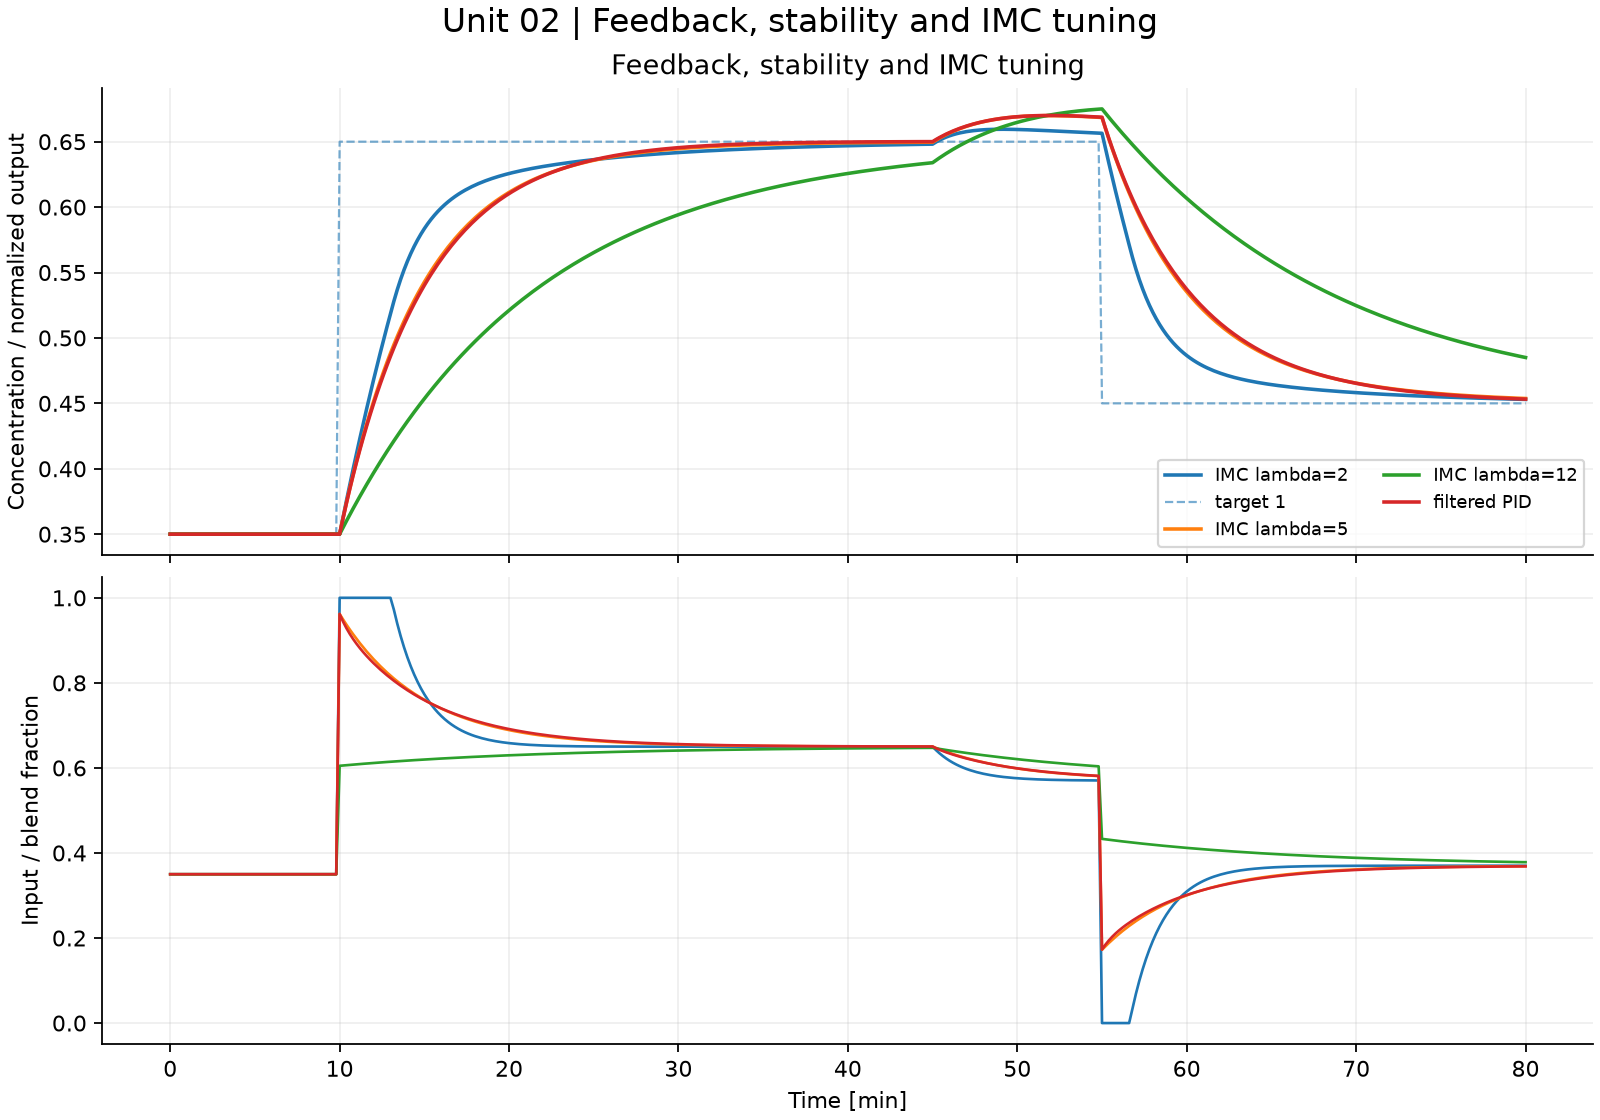

In [3]:
from IPython.display import Image, display
display(Image(filename=str(ROOT / "laboratories/02-feedback-imc/results/comparison.png")))

## Inspect the evidence

1. Identify the physical assumptions, input limits and units.
2. Explain a visible transient using the governing equation.
3. Change one model or controller parameter, rerun and compare the saved metrics.
4. State what the test does and does not establish.

Use the [course guide](https://github.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/blob/main/course/README.md), [worked problems](https://github.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/blob/main/problem-sets/README.md) and [benchmark inventory](https://github.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/blob/main/benchmarks/README.md) for the corresponding derivations and extensions.

## Apply this unit to the article benchmarks

[Worked benchmark study for Unit 02](https://github.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/blob/main/benchmarks/learning/unit-02.md)

![Unit 02 benchmark study](https://raw.githubusercontent.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/main/benchmarks/learning/figures/unit-02.png)

Read the per-model method, chosen signals, numerical results and interpretation in the linked study. The learning track declares its local-model approximations and separates equation-based experiments from external datasets and simulators. It does not turn an unavailable measured record into a synthetic benchmark result.